In [1]:
import os
import kagglehub
import pandas as pd
from pathlib import Path
import duckdb
import sklearn
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from datetime import datetime
from dateutil.relativedelta import relativedelta

In [2]:
#This script loads the raw data - only need to run one time so this is commented out
#!python lending_load_raw.py

PROJECT_PATH = Path(Path.cwd().resolve())

#set the path to the database
DB_PATH = PROJECT_PATH / "data" / "lending.duckdb"

#set the duckdb connection
con = duckdb.connect(DB_PATH)

In [3]:
#pull in sample data sets so that we can check on things in the raw data

#Some sample datasets so I can review
df_r_s = con.sql('SELECT * from RAW_REJECTED LIMIT 1000').df()  #rejected sample
df_a_s = con.sql('SELECT * FROM raw_accepted LIMIT 1000').df()  #accepted sample
df_ls = con.sql('SELECT * from loans_scoped').df() #scoped loans
df_f = con.sql('SELECT * FROM funnel_qtr').df() #funnel info


In [4]:
#Quarterly KPI Table

df_kpi = con.sql("""
                SELECT  l.issue_qtr,
                        f.qtr_name,
                        count(l.id) as loans_booked,
                        sum(l.funded_amnt) as dollars_booked,
                        mean(l.funded_amnt) as avg_loan,
                        (sum(l.funded_amnt * int_rate) / sum(l.funded_amnt)) as weighted_int,
                        mean(l.bad_flag) as bad_rate,
                        f.approval_rate as "approval_rate_all_terms"

                FROM loans_scoped l
                LEFT JOIN funnel_qtr f on cast(l.issue_qtr as DATE) = cast(f.qtr_start as DATE)

                GROUP BY l.issue_qtr, f.qtr_name, f.approval_rate
                
                ORDER BY l.issue_qtr


                """).df()

In [5]:
#print some loan stats so we can see how things changed from the beginning of the dataset

print("Loan Statistics:")
print(f"Loans Q1 2012 - Total Loans: {df_kpi.loc[df_kpi['qtr_name'] == '2012-Q1', 'loans_booked'].item():,.0f}  | Dollars Booked: ${df_kpi.loc[df_kpi['qtr_name'] == '2012-Q1', 'dollars_booked'].item():,.0f}    | Approval Rate: {df_kpi.loc[df_kpi['qtr_name'] == '2012-Q1', 'approval_rate_all_terms'].item():.2%}")
print(f"Loans Q4 2015 - Total Loans: {df_kpi.loc[df_kpi['qtr_name'] == '2015-Q4', 'loans_booked'].item():,.0f} | Dollars Booked: ${df_kpi.loc[df_kpi['qtr_name'] == '2015-Q4', 'dollars_booked'].item():,.0f} | Approval Rate: {df_kpi.loc[df_kpi['qtr_name'] == '2015-Q4', 'approval_rate_all_terms'].item():.2%}")

Loan Statistics:
Loans Q1 2012 - Total Loans: 6,498  | Dollars Booked: $77,296,100    | Approval Rate: 12.51%
Loans Q4 2015 - Total Loans: 88,669 | Dollars Booked: $1,127,452,175 | Approval Rate: 12.67%


Module 1 - Lending Portfolio Stats

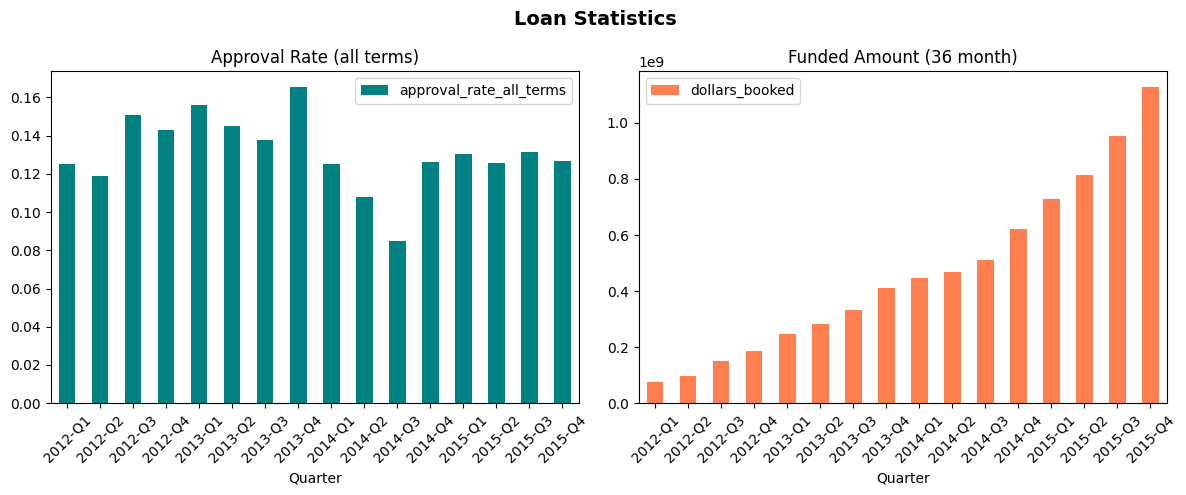

In [6]:
#Module 1 -  funded rate and total loans

#set the initial plot information
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

#set the first axis for the approval rates
df_kpi.plot(kind='bar', ax = ax1, x = 'qtr_name', y = 'approval_rate_all_terms', color = 'teal',rot =45)
ax1.set_title('Approval Rate (all terms)')

#set the second axis for dollars booked
df_kpi.plot(kind='bar',ax = ax2, x = 'qtr_name', y = 'dollars_booked', color = 'coral',rot =45)
ax2.set_title('Funded Amount (36 month)')

#set some final values and show the plot
plt.suptitle('Loan Statistics', fontsize=14, weight='bold')
ax1.set_xlabel('Quarter')
ax2.set_xlabel('Quarter')

#show the plot
plt.tight_layout()

#save the file to the output folder
plt.savefig(PROJECT_PATH / "output" / "lending_m1_volume_approval.png", dpi=150, bbox_inches="tight")

plt.show()


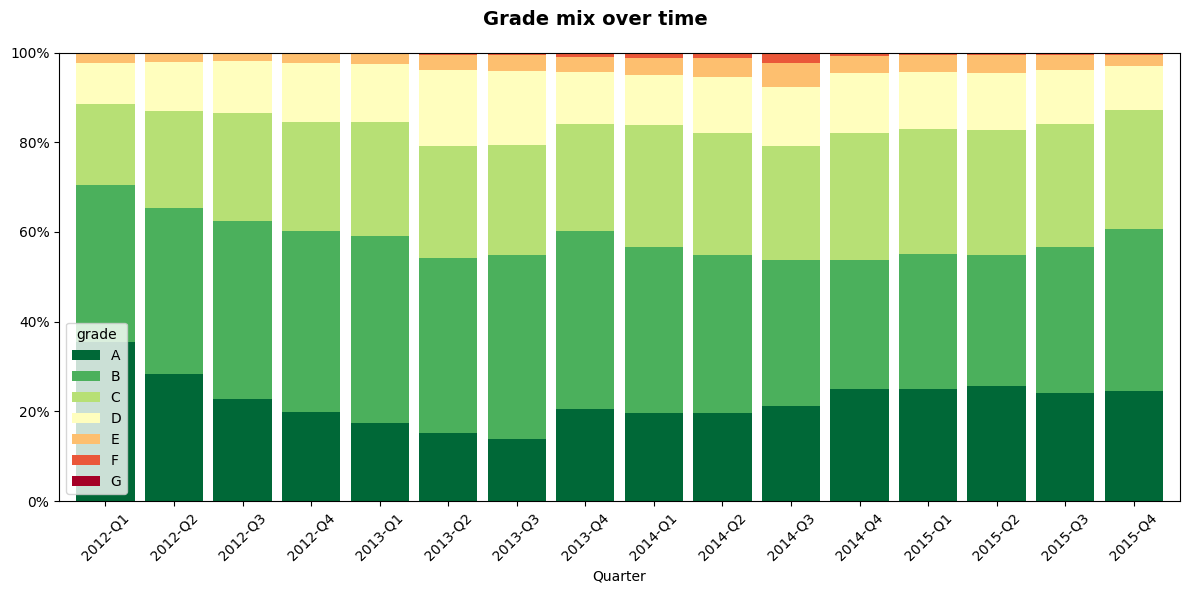

In [7]:
#Module 1 - time series - grade mix over time

fig, ax = plt.subplots(figsize=(12, 6))

#create the bar chart
df_mix = pd.crosstab(df_ls['qtr_name'], df_ls['grade'], normalize='index')
df_mix.plot(kind='bar', stacked=True, ax=ax, rot=45, width=0.85, colormap='RdYlGn_r')

#format the y-axis as a percentage
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))

#set some final values and show the plot
plt.suptitle('Grade mix over time', fontsize=14, weight='bold')
plt.xlabel('Quarter')

#show the plot
plt.tight_layout()

#save the file to the output folder
plt.savefig(PROJECT_PATH / "output" / "lending_grade_mix.png", dpi=150, bbox_inches="tight")

plt.show()


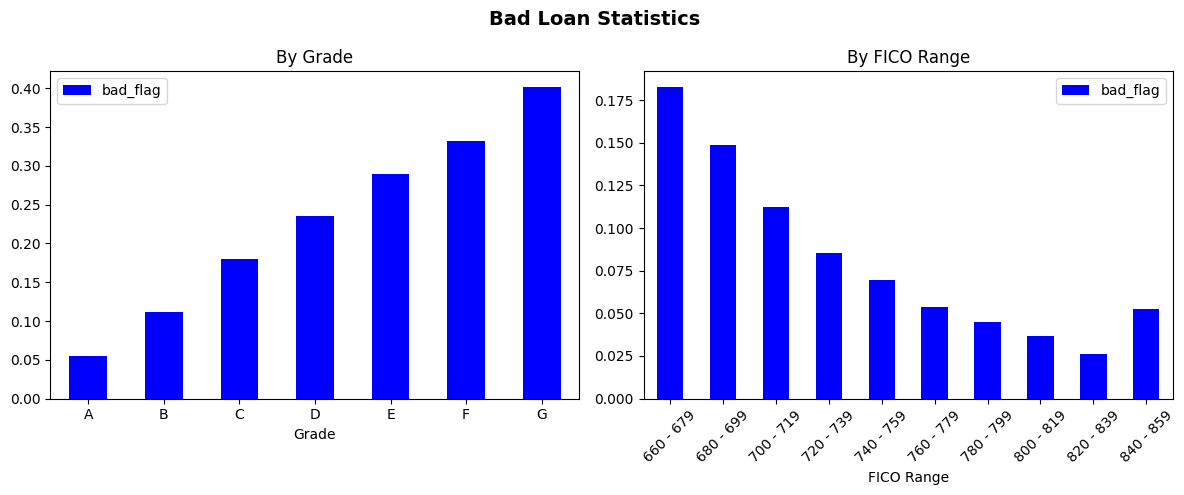

In [8]:
#Module 1 - FICO chart

#create a range based on the max and min FICO scores
fico_rng = range(df_ls['fico_range_low'].min(),df_ls['fico_range_high'].max(), 20)

#create a dataframe shell to hold the loan data
df_fico = pd.DataFrame(fico_rng, columns=["fico_min"])
df_fico['fico_max'] = df_fico['fico_min'] + 19

#create a new dataframe with just a few columns
df_ls_m = df_ls[['fico_mid','bad_flag']].sort_values('fico_mid')

#create a summary of grade and average bad_flag
df_ls_bg = df_ls.groupby('grade')['bad_flag'].mean().reset_index()

#merge where the mid fico score is in the range
df_fico = pd.merge_asof(df_ls_m, df_fico, left_on='fico_mid', right_on='fico_min', direction='backward')

#make a column that plainly states the fico range
df_fico['fico_rng'] = df_fico['fico_min'].astype(str) + " - " + df_fico['fico_max'].astype(str)

#group by the range and grade, average the bad_flag
df_fico = df_fico.groupby(['fico_rng'], as_index = True)['bad_flag'].mean().reset_index()

#set the initial plot information
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

#set the first axis grades
df_ls_bg.plot(kind='bar', ax = ax1, x = 'grade', y = 'bad_flag', color = 'blue',rot =0)
ax1.set_title('By Grade')
ax1.set_xlabel('Grade')

#set the second axis for the FICO range
df_fico.plot(kind='bar', ax = ax2, x = 'fico_rng', y = 'bad_flag', color = 'blue',rot =45)
ax2.set_title('By FICO Range')
ax2.set_xlabel('FICO Range')

#set some final values and show the plot
plt.suptitle('Bad Loan Statistics', fontsize=14, weight='bold')
plt.tight_layout()

#save the file to the output folder
plt.savefig(PROJECT_PATH / "output" / "lending_bad_loans.png", dpi=150, bbox_inches="tight")

plt.show()


Module 2 - Vintage Loss Curves

In [9]:
#Module 2 - Vintage loss curves

#First add some columns to help with this analysis

#add default months on book
df_ls['default_mob'] = (df_ls['last_pymnt_d_date'].dt.to_period('M').astype(int) - df_ls['issue_date'].dt.to_period('M').astype(int))

#fill in 0's 
df_ls.loc[df_ls['last_pymnt_d'].isnull(), 'default_mob'] = 0
df_ls['vintage'] = df_ls['issue_date'].dt.year

In [10]:
#Function in support of Module 2
#create a function to make the calculation of the vintage curve more repeatable

def vintage_curve(df):
    
    #group by vintage and default_mob
    vm = df.groupby(['vintage', 'default_mob'])['bad_flag'].sum().reset_index()

    #pivot so mob is across the columns
    curve = vm.pivot_table(values='bad_flag', index='default_mob',
                           columns='vintage', fill_value=0).reindex(range(37), fill_value=0)

    #return the running total of defaults, divided by ALL loans in each vintage
    return curve.cumsum() / df.groupby('vintage')['id'].count()

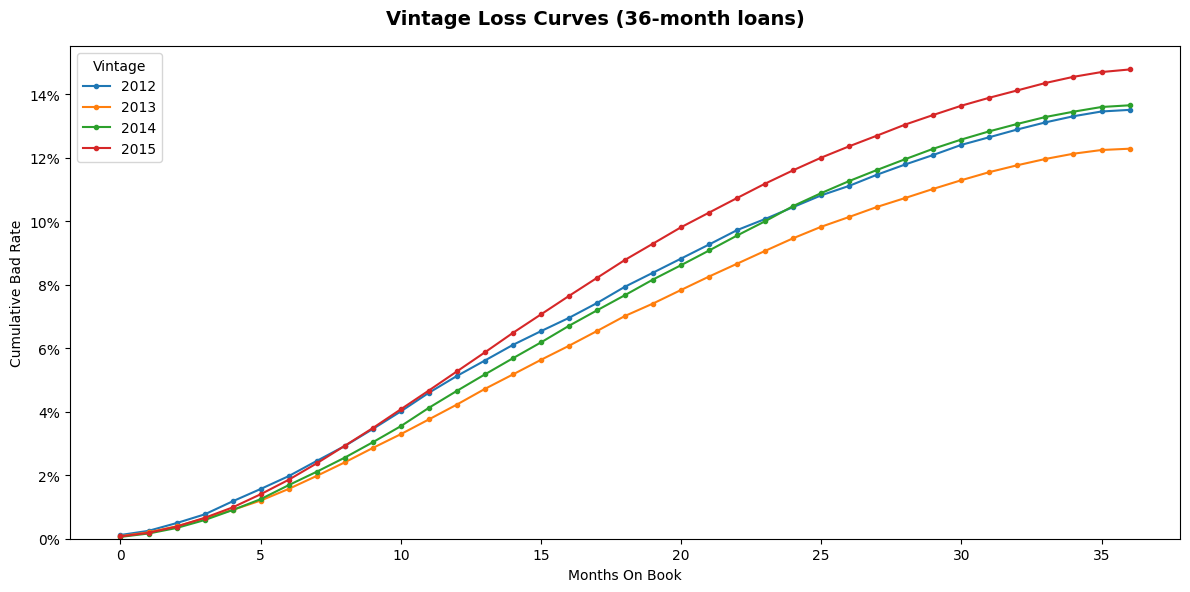

In [11]:
#Module 2A - Vintage loss curves
df_curve = vintage_curve(df_ls) 

#create the framework
fig, ax = plt.subplots(figsize=(12, 6))

#create the plot
df_curve.plot.line(ax = ax, xlabel = 'Months On Book', ylabel = 'Cumulative Bad Rate', marker = '.')

#some formatting items
ax.legend(title='Vintage')                                                       #label the legend
ax.set_ylim(0, df_curve.max().max() * 1.05)                                      #make the axis ranges the same 
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))         #format as percentages
plt.suptitle('Vintage Loss Curves (36-month loans)', fontsize=14, weight='bold') #set the title

#show the plot
plt.tight_layout()

#save the file to the output folder
plt.savefig(PROJECT_PATH / "output" / "vintage_curves.png", dpi=150, bbox_inches="tight")

plt.show()


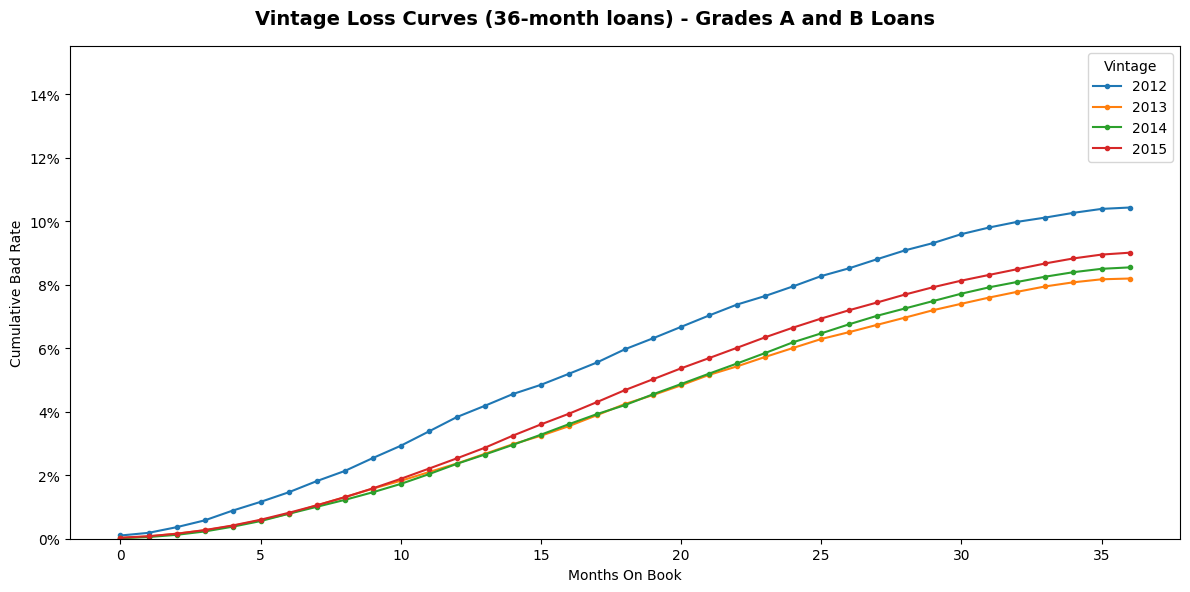

In [12]:
#Module 2B - Vintage loss curves but only grades A and B

#create the vintage curve 
df_curve_AB = vintage_curve(df_ls[df_ls['grade'].isin(['A','B'])])

#create the framework
fig, ax = plt.subplots(figsize=(12, 6))

#create the plot
df_curve_AB.plot.line(ax = ax, xlabel = 'Months On Book', ylabel = 'Cumulative Bad Rate', marker = '.')

#some formatting items
ax.legend(title='Vintage')                                                       #label the legend
ax.set_ylim(0, df_curve.max().max() * 1.05)                                      #make the axis ranges the same
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))         #format as percentages
plt.suptitle('Vintage Loss Curves (36-month loans) - Grades A and B Loans', fontsize=14, weight='bold') #set the title

#show the plot
plt.tight_layout()

#save the file to the output folder
plt.savefig(PROJECT_PATH / "output" / "vintage_curves_AB.png", dpi=150, bbox_inches="tight")

plt.show()

Module 3 - Pricing and Risk-Adjusted Return

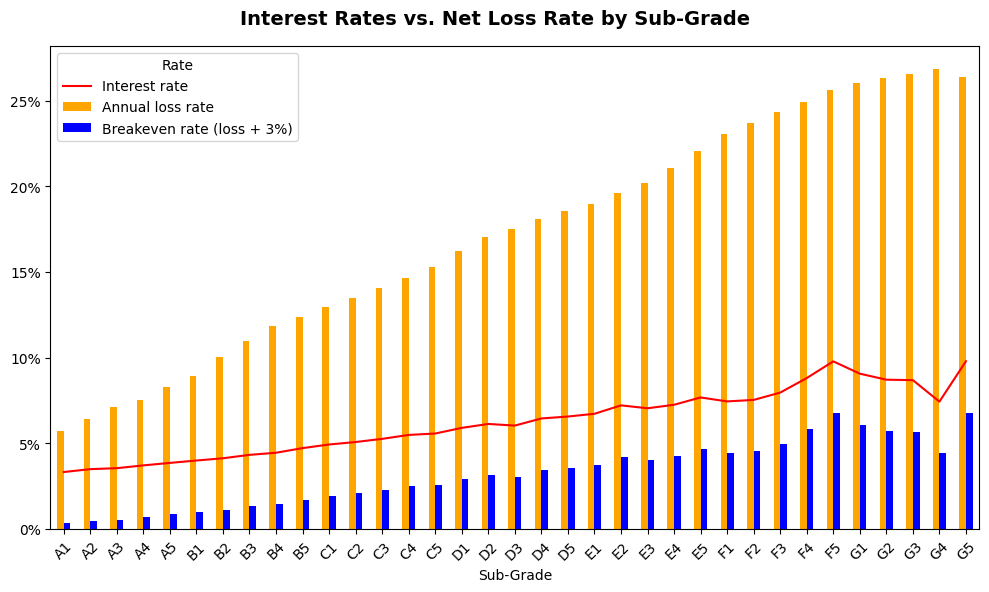

In [13]:
#create a variable for the cost of funds used below
cf = .03

#group interest rates by the subgrade
df_ls_sg_sm = df_ls.groupby(['sub_grade'])['int_rate'].mean().reset_index()

#calculate a few extra columns in df_ls so we can calculate the remainin stats here
df_ls['net_loss'] = (df_ls['funded_amnt'] - df_ls['total_pymnt']).clip(lower=0) #take funded amount less total payment, cap at 0

#summarize the additional metrics by sub-grade
df_ls_fndamt = df_ls.groupby(['sub_grade'])['funded_amnt'].sum().reset_index()
df_ls_nlp_sm = df_ls.groupby(['sub_grade'])['net_loss'].sum().reset_index()

#join in some additional aggregated data
df_ls_sg_sm = df_ls_sg_sm.merge(df_ls_fndamt, how='left', on='sub_grade')
df_ls_sg_sm = df_ls_sg_sm.merge(df_ls_nlp_sm, how='left', on='sub_grade')

#calculate some additional items
df_ls_sg_sm['net_loss_rate_an'] = (df_ls_sg_sm['net_loss'] / df_ls_sg_sm['funded_amnt']) / 3
df_ls_sg_sm['risk_adj_margin'] = df_ls_sg_sm['int_rate']/100 - df_ls_sg_sm['net_loss_rate_an'] - cf

df_ls_sg_sm_p = df_ls_sg_sm[['sub_grade','int_rate','net_loss_rate_an']].copy()
df_ls_sg_sm_p['int_rate'] = df_ls_sg_sm_p['int_rate'] / 100
df_ls_sg_sm_p['breakeven'] = df_ls_sg_sm_p['net_loss_rate_an'] + cf

# Plot the bar chart first
ax = df_ls_sg_sm_p.plot(kind='bar', x='sub_grade', xlabel = 'Sub-Grade', y=['int_rate','net_loss_rate_an'], color=['orange','blue'], figsize=(10, 6))

#create the plot
df_ls_sg_sm_p.plot(kind='line', ax = ax, y = 'breakeven', color='red', rot=45)

#clean up the legend
ax.legend(['Interest rate', 'Annual loss rate', 'Breakeven rate (loss + 3%)'], title='Rate')    
                                                  
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))         #format as percentages
plt.suptitle('Interest Rates vs. Net Loss Rate by Sub-Grade', fontsize=14, weight='bold') #set the title

#make it a tight layout
plt.tight_layout()

#save the file to the output folder
plt.savefig(PROJECT_PATH / "output" / "ir_nlr.png", dpi=150, bbox_inches="tight")

#show the plot
plt.show()


In [15]:
#close the database connection
con.close()